# Flood-response SoS analysis


In [10]:
from pathlib import Path
import json
import math

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

# Find the project root when launched from the project folder, a child folder
# such as output/, or the repository folder containing flood_sos/.
candidates = [Path.cwd(), *Path.cwd().parents]
candidates.extend([path / "flood_sos" for path in candidates])
project_dir = next(
    (path for path in candidates if (path / "output" / "simulation_runs.csv").exists()),
    None,
)
if project_dir is None:
    raise FileNotFoundError("Could not find output/simulation_runs.csv from this notebook's working directory.")

output_dir = project_dir / "output"
runs_all = pd.read_csv(output_dir / "simulation_runs.csv")
flood_all = pd.read_csv(output_dir / "flood_history.csv")
with (output_dir / "simulation_summary.json").open(encoding="utf-8") as file:
    summary = json.load(file)

# Change this value to analyze another matched rescue-sensitivity condition.
selected_rescue_sensitivity = "boat_emphasis"
if "rescue_sensitivity" in runs_all.columns:
    available_sensitivities = set(runs_all["rescue_sensitivity"].dropna())
    if selected_rescue_sensitivity not in available_sensitivities:
        raise ValueError(
            f"Rescue-sensitivity condition {selected_rescue_sensitivity!r} is unavailable. "
            f"Available: {sorted(available_sensitivities)}"
        )
    runs = runs_all.loc[
        runs_all["rescue_sensitivity"] == selected_rescue_sensitivity
    ].copy()
    flood = flood_all.loc[
        flood_all["rescue_sensitivity"] == selected_rescue_sensitivity
    ].copy()
else:
    runs = runs_all.copy()
    flood = flood_all.copy()
    selected_rescue_sensitivity = "all available runs"

scenario_order = ["low_only", "high_only", "mixed"]
scenario_labels = {
    "low_only": "St. permissive",
    "high_only": "St. restrictive",
    "mixed": "Dynamic",
}
scenario_colors = {
    "low_only": "#777777",  # Preserve Static permissive's current color.
    "high_only": "darkorange",
    "mixed": "dodgerblue",
}
scenario_line_styles = {"low_only": "-", "high_only": "--", "mixed": "-."}
configuration_order = ["reduced_departure", "baseline", "increased_departure"]
configuration_labels = {
    "reduced_departure": "Low",
    "baseline": "Ref.",
    "increased_departure": "High",
}
configuration_markers = {
    "reduced_departure": "o",
    "baseline": "s",
    "increased_departure": "^",
}

# Match the reference notebook's compact, paper-oriented matplotlib style.
plt.rcParams.update({
    "font.family": "serif",
    "font.size": 8,
    "axes.titlesize": 8,
    "axes.labelsize": 8,
    "xtick.labelsize": 7,
    "ytick.labelsize": 7,
    "legend.fontsize": 7,
    "axes.linewidth": 0.6,
    "xtick.major.width": 0.6,
    "ytick.major.width": 0.6,
    "xtick.major.size": 2.5,
    "ytick.major.size": 2.5,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
})

def format_axis(ax):
    ax.grid(axis="y", linewidth=0.3, alpha=0.5)
    ax.set_axisbelow(True)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.tick_params(axis="x", pad=1.5)

plot_dir = project_dir / "plots"
plot_dir.mkdir(exist_ok=True)


def print_plot_values(title, values, scope=None):
    """Print the actual plotted aggregates with readable labels and no truncation."""
    table = values.copy()
    table = table.rename(columns={
        "scenario": "Policy strategy",
        "profile_configuration": "Departure rate",
    })
    if "Policy strategy" in table.columns:
        table["Policy strategy"] = table["Policy strategy"].map(
            lambda value: scenario_labels.get(value, value)
        )
    if "Departure rate" in table.columns:
        table["Departure rate"] = table["Departure rate"].map(
            lambda value: configuration_labels.get(value, value)
        )
    print(f"\n{title}")
    print(f"Sensitivity condition: {selected_rescue_sensitivity}")
    if scope:
        print(scope)
    print(table.to_string(index=False, max_rows=None, max_cols=None,
                          float_format=lambda value: f"{value:.6f}"))

rate_definitions = summary.get("experiment", {}).get("profile_configurations", {})
print("Departure-rate labels (requests per eligible constituent per simulated minute):")
for configuration in configuration_order:
    rate = rate_definitions.get(configuration, {}).get("Reactive", {}).get("departure_rate")
    print(f"  {configuration_labels[configuration]}: {rate if rate is not None else configuration}")


Departure-rate labels (requests per eligible constituent per simulated minute):
  Low: 0.04
  Ref.: 0.08
  High: 0.16


## Mission objective achievement across runs


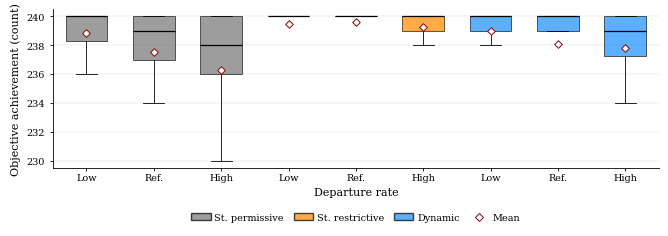


Mission objective achievement across runs
Sensitivity condition: boat_emphasis
Policy strategy Departure rate  Runs  Mean achievement (count)  Median achievement (count)  Q1 (count)  Q3 (count)  Lower whisker (count)  Upper whisker (count)
 St. permissive            Low    30                238.866667                  240.000000  238.250000  240.000000                    236                    240
 St. permissive           Ref.    30                237.533333                  239.000000  237.000000  240.000000                    234                    240
 St. permissive           High    30                236.266667                  238.000000  236.000000  240.000000                    230                    240
St. restrictive            Low    30                239.466667                  240.000000  240.000000  240.000000                    240                    240
St. restrictive           Ref.    30                239.566667                  240.000000  240.000000  240.000000 

In [11]:
objective_column = (
    "mission_objective_achievement"
    if "mission_objective_achievement" in runs.columns
    else next(column for column in runs.columns if column.endswith(("_completed_before_deadline", "_rescued_before_deadline")))
)

condition_order = [
    (strategy, configuration)
    for strategy in scenario_order
    for configuration in configuration_order
    if ((runs["scenario"] == strategy) & (runs["profile_configuration"] == configuration)).any()
]
condition_values = [
    runs.loc[
        (runs["scenario"] == strategy)
        & (runs["profile_configuration"] == configuration),
        objective_column,
    ].dropna().to_numpy()
    for strategy, configuration in condition_order
]
short_configuration_labels = {
    "reduced_departure": "Low",
    "baseline": "Ref.",
    "increased_departure": "High",
}
condition_labels = [
    short_configuration_labels.get(configuration, configuration)
    for _, configuration in condition_order
]

fig, ax = plt.subplots(figsize=(6.6, 2.65))
box = ax.boxplot(
    condition_values,
    patch_artist=True,
    showfliers=False,
    widths=0.62,
    medianprops={"color": "black", "linewidth": 0.9},
    whiskerprops={"color": "black", "linewidth": 0.6},
    capprops={"color": "black", "linewidth": 0.6},
)
for patch, (strategy, _) in zip(box["boxes"], condition_order):
    patch.set_facecolor(scenario_colors[strategy])
    patch.set_edgecolor("black")
    patch.set_linewidth(0.6)
    patch.set_alpha(0.72)

means = [values.mean() if len(values) else np.nan for values in condition_values]
ax.scatter(
    np.arange(1, len(means) + 1), means,
    marker="D", s=15, facecolor="white", edgecolor="darkred", linewidth=0.7,
    zorder=4,
)
ax.set_xticks(np.arange(1, len(condition_labels) + 1))
ax.set_xticklabels(condition_labels, rotation=0, ha="center", fontsize=7)
ax.set_xlabel("Departure rate", labelpad=3)
ax.set_ylabel("Objective achievement (count)")
#ax.set_title("Mission objective achievement across runs")
format_axis(ax)
legend_handles = [
    Patch(facecolor=scenario_colors[strategy], edgecolor="black", alpha=0.72,
          label=scenario_labels[strategy])
    for strategy in scenario_order if strategy in runs["scenario"].unique()
]
legend_handles.append(
    Line2D([0], [0], marker="D", color="darkred", markerfacecolor="white",
           markeredgewidth=0.7, linestyle="None", markersize=4, label="Mean")
)
ax.legend(handles=legend_handles, frameon=False, ncol=4, loc="upper center",
          bbox_to_anchor=(0.5, -0.23), columnspacing=1.0, handletextpad=0.4)
fig.tight_layout(rect=(0, 0.10, 1, 1), pad=0.5)
fig.savefig(plot_dir / "mission_objective_achievement_across_runs.pdf", bbox_inches="tight", pad_inches=0.02)
plt.show()


# Match matplotlib's default 1.5-IQR whiskers; outliers are hidden in the plot.
from matplotlib.cbook import boxplot_stats
objective_box_rows = []
for (strategy, configuration), values in zip(condition_order, condition_values):
    if not len(values):
        continue
    stats = boxplot_stats(values, whis=1.5)[0]
    objective_box_rows.append({
        "scenario": strategy,
        "profile_configuration": configuration,
        "Runs": len(values),
        "Mean achievement (count)": stats["mean"],
        "Median achievement (count)": stats["med"],
        "Q1 (count)": stats["q1"],
        "Q3 (count)": stats["q3"],
        "Lower whisker (count)": stats["whislo"],
        "Upper whisker (count)": stats["whishi"],
    })
print_plot_values("Mission objective achievement across runs",
                  pd.DataFrame(objective_box_rows))


## Flood trajectory


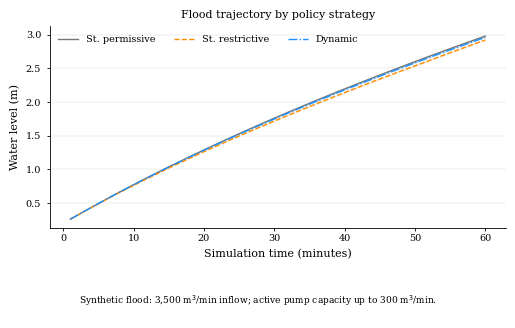


Flood trajectory
Sensitivity condition: boat_emphasis
Departure-rate conditions are pooled, as in the plot. Bands use mean +/- 1.96 * SD / sqrt(observations).
Policy strategy  Simulation time (min)  Mean water level (m)  Water-level SD (m)  Observations  Lower plotted band (m)  Upper plotted band (m)
St. restrictive               1.000000              0.260000            0.000000            90                0.260000                0.260000
St. restrictive               2.000000              0.319111            0.000741            90                0.318958                0.319264
St. restrictive               3.000000              0.377389            0.001714            90                0.377035                0.377743
St. restrictive               4.000000              0.434744            0.002974            90                0.434130                0.435359
St. restrictive               5.000000              0.491167            0.004309            90                0.490276       

In [12]:
flood_stats = (
    flood.groupby(["scenario", "time_minutes"], observed=True)["water_level_m"]
    .agg(mean="mean", std="std", count="count")
    .reset_index()
)
fig, ax = plt.subplots(figsize=(5.2, 3.25))
for strategy in scenario_order:
    part = flood_stats.loc[flood_stats["scenario"] == strategy].sort_values("time_minutes")
    if part.empty:
        continue
    ci = 1.96 * part["std"].fillna(0) / np.sqrt(part["count"].clip(lower=1))
    ax.plot(part["time_minutes"], part["mean"], color=scenario_colors[strategy],
            linestyle=scenario_line_styles[strategy], linewidth=1.0,
            label=scenario_labels[strategy])
    ax.fill_between(part["time_minutes"], part["mean"] - ci, part["mean"] + ci,
                    color=scenario_colors[strategy], alpha=0.14, linewidth=0)
ax.set_xlabel("Simulation time (minutes)")
ax.set_ylabel("Water level (m)")
ax.set_title("Flood trajectory by policy strategy")
format_axis(ax)
ax.legend(frameon=False, ncol=3, loc="upper left")
fig.tight_layout(rect=(0, 0.16, 1, 1))
fig.text(
    0.5, 0.015,
    "Synthetic flood: 3,500 m$^3$/min inflow; active pump capacity up to 300 m$^3$/min.\n",
    ha="center", va="bottom", fontsize=6.5,
)
fig.savefig(plot_dir / "flood_trajectory.pdf", bbox_inches="tight")
plt.show()


flood_print = flood_stats.copy()
flood_band = 1.96 * flood_print["std"].fillna(0) / np.sqrt(flood_print["count"].clip(lower=1))
flood_print["Lower plotted band (m)"] = flood_print["mean"] - flood_band
flood_print["Upper plotted band (m)"] = flood_print["mean"] + flood_band
flood_print = flood_print.rename(columns={
    "time_minutes": "Simulation time (min)", "mean": "Mean water level (m)",
    "std": "Water-level SD (m)", "count": "Observations",
})
print_plot_values("Flood trajectory", flood_print,
                  "Departure-rate conditions are pooled, as in the plot. "
                  "Bands use mean +/- 1.96 * SD / sqrt(observations).")


## Mission objective achievement over time


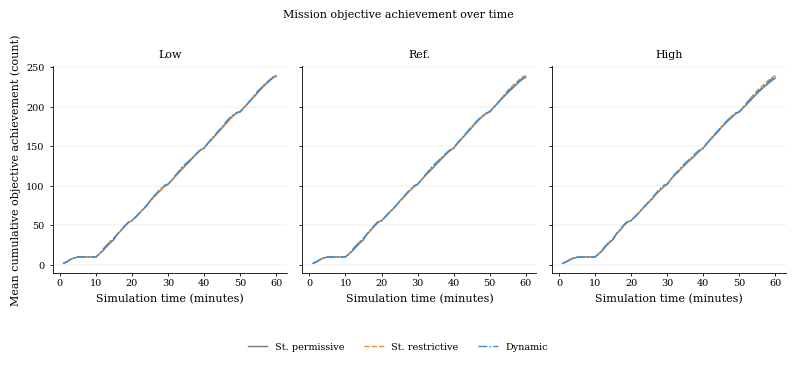


Mission objective achievement over time
Sensitivity condition: boat_emphasis
Bands use mean +/- 1.96 * SD / sqrt(observations).
Departure rate Policy strategy  Simulation time (min)  Mean cumulative objective achievement (count)  Objective-achievement SD (count)  Observations  Lower plotted band (count)  Upper plotted band (count)
          Ref. St. restrictive               1.000000                                       2.000000                          0.000000            30                    2.000000                    2.000000
          Ref. St. restrictive               2.000000                                       4.000000                          0.000000            30                    4.000000                    4.000000
          Ref. St. restrictive               3.000000                                       7.000000                          0.000000            30                    7.000000                    7.000000
          Ref. St. restrictive               4.0000

In [13]:
objective_column = (
    "mission_objective_achievement"
    if "mission_objective_achievement" in flood.columns
    else next(column for column in flood.columns if column.endswith(("_completed_before_deadline", "_rescued_before_deadline")))
)
objective_stats = (
    flood.groupby(["profile_configuration", "scenario", "time_minutes"], observed=True)[
        objective_column
    ]
    .agg(mean="mean", std="std", count="count")
    .reset_index()
)
fig, axes = plt.subplots(1, len(configuration_order), figsize=(8.0, 3.0), sharey=True)
for ax, configuration in zip(axes, configuration_order):
    config_stats = objective_stats.loc[
        objective_stats["profile_configuration"] == configuration
    ]
    for strategy in scenario_order:
        part = config_stats.loc[config_stats["scenario"] == strategy].sort_values("time_minutes")
        if part.empty:
            continue
        ci = 1.96 * part["std"].fillna(0) / np.sqrt(part["count"].clip(lower=1))
        ax.plot(part["time_minutes"], part["mean"], color=scenario_colors[strategy],
                linestyle=scenario_line_styles[strategy], linewidth=1.0,
                label=scenario_labels[strategy])
        ax.fill_between(part["time_minutes"], part["mean"] - ci, part["mean"] + ci,
                        color=scenario_colors[strategy], alpha=0.14, linewidth=0)
    ax.set_title(configuration_labels.get(configuration, configuration))
    ax.set_xlabel("Simulation time (minutes)")
    format_axis(ax)
axes[0].set_ylabel("Mean cumulative objective achievement (count)")
fig.suptitle("Mission objective achievement over time", y=1.02, fontsize=8)
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, frameon=False, ncol=len(scenario_order),
           loc="upper center", bbox_to_anchor=(0.5, -0.06))
fig.tight_layout()
fig.savefig(plot_dir / "mission_objective_achievement_over_time.pdf", bbox_inches="tight")
plt.show()


objective_print = objective_stats.copy()
objective_band = 1.96 * objective_print["std"].fillna(0) / np.sqrt(objective_print["count"].clip(lower=1))
objective_print["Lower plotted band (count)"] = objective_print["mean"] - objective_band
objective_print["Upper plotted band (count)"] = objective_print["mean"] + objective_band
objective_print = objective_print.rename(columns={
    "time_minutes": "Simulation time (min)",
    "mean": "Mean cumulative objective achievement (count)",
    "std": "Objective-achievement SD (count)", "count": "Observations",
})
print_plot_values("Mission objective achievement over time", objective_print,
                  "Bands use mean +/- 1.96 * SD / sqrt(observations).")


## Mission success versus mean base cost


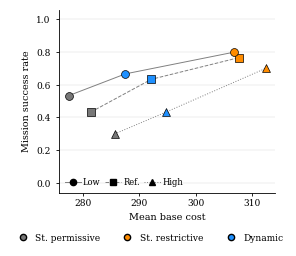


Mission success versus mean base cost
Sensitivity condition: boat_emphasis
Coordinates are the JSON summary aggregates used in the plot; costs use illustrative cost units.
Policy strategy Departure rate  Mission success rate (0-1)  Mean base cost  Mission success rate (%)
 St. permissive           Ref.                    0.433333      281.490862                 43.333333
 St. permissive            Low                    0.533333      277.547194                 53.333333
 St. permissive           High                    0.300000      285.720534                 30.000000
St. restrictive           Ref.                    0.766667      307.732359                 76.666667
St. restrictive            Low                    0.800000      306.863792                 80.000000
St. restrictive           High                    0.700000      312.362565                 70.000000
        Dynamic           Ref.                    0.633333      292.160609                 63.333333
        Dynamic    

In [14]:
summary_rows = []
for condition, values in summary.get("aggregates", {}).items():
    parts = condition.split("/")
    if len(parts) != 3:
        continue
    strategy, configuration, sensitivity = parts
    if sensitivity != selected_rescue_sensitivity:
        continue
    summary_rows.append({
        "scenario": strategy,
        "profile_configuration": configuration,
        "success_rate": values["success_rate"],
        "mean_cost_base": values["mean_cost_base"],
    })

cost_summary = pd.DataFrame(summary_rows)
if cost_summary.empty:
    raise ValueError("No matching conditions found in simulation_summary.json for the selected sensitivity.")
cost_unit = summary.get("experiment", {}).get("cost_model", {}).get(
    "cost_unit", "cost units"
)

fig, ax = plt.subplots(figsize=(2.65, 2.9))
configuration_line_styles = {"reduced_departure": "-", "baseline": "--", "increased_departure": ":"}
for configuration in configuration_order:
    points = cost_summary.loc[
        cost_summary["profile_configuration"] == configuration
    ].sort_values("mean_cost_base")
    ax.plot(points["mean_cost_base"], points["success_rate"],
            color="0.5", linestyle=configuration_line_styles[configuration],
            linewidth=0.7, zorder=2)
for _, row in cost_summary.iterrows():
    ax.scatter(
        row["mean_cost_base"], row["success_rate"],
        marker=configuration_markers.get(row["profile_configuration"], "o"),
        color=scenario_colors.get(row["scenario"], "black"),
        edgecolor="black", linewidth=0.5, s=32, zorder=3,
    )
ax.set_xlabel("Mean base cost", fontsize=7)
ax.set_ylabel("Mission success rate", fontsize=7)
ax.set_ylim(-0.06, 1.06)
# The paper subfigure caption supplies the title.
from matplotlib.ticker import MaxNLocator
ax.xaxis.set_major_locator(MaxNLocator(nbins=4))
ax.tick_params(labelsize=6.5)
format_axis(ax)
scenario_handles = [
    Line2D([0], [0], marker="o", color="none", markerfacecolor=scenario_colors[s],
           markeredgecolor="black", markersize=4.5, label=scenario_labels[s])
    for s in scenario_order if s in cost_summary["scenario"].unique()
]
configuration_handles = [
    Line2D([0], [0], marker=configuration_markers[c], color="0.5",
           markerfacecolor="black", markeredgecolor="black",
           linestyle=configuration_line_styles[c], linewidth=0.7,
           markersize=4.5, label=configuration_labels[c])
    for c in configuration_order if c in cost_summary["profile_configuration"].unique()
]
fig.legend(handles=scenario_handles, frameon=False, loc="lower center",
           ncol=3, fontsize=6.5, handletextpad=0.4, labelspacing=0.25,
           bbox_to_anchor=(0.5, 0.15))
ax.legend(handles=configuration_handles, frameon=False, loc="lower left",
          ncol=3, fontsize=6, columnspacing=0.5, handletextpad=0.2,
          borderaxespad=0.3)
fig.tight_layout(rect=(0, 0.23, 1, 1), pad=0.5)
fig.savefig(plot_dir / "mission_success_vs_mean_base_cost.pdf", bbox_inches="tight", pad_inches=0.02)
plt.show()


cost_print = cost_summary.rename(columns={
    "success_rate": "Mission success rate (0-1)",
    "mean_cost_base": "Mean base cost",
})
cost_print["Mission success rate (%)"] = cost_print["Mission success rate (0-1)"] * 100
print_plot_values("Mission success versus mean base cost", cost_print,
                  f"Coordinates are the JSON summary aggregates used in the plot; costs use {cost_unit}.")


## State transitions by profile and departure rate


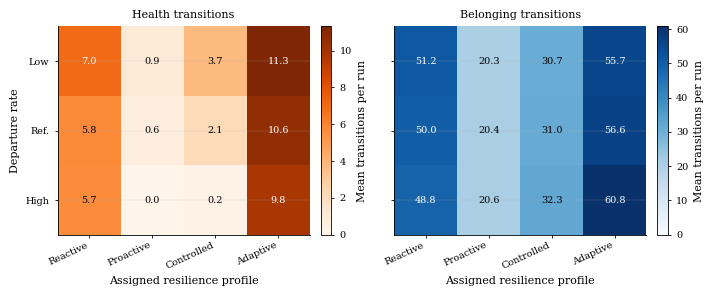


State transitions by profile and departure rate
Sensitivity condition: boat_emphasis
Same profile pooling and zero-filled cells as the heatmaps; means include runs in which the profile was observed.
Departure rate Resilience profile    Region  Mean transitions per run
           Low           Reactive    Health                  6.950000
           Low          Proactive    Health                  0.933333
           Low         Controlled    Health                  3.733333
           Low           Adaptive    Health                 11.316667
          Ref.           Reactive    Health                  5.766667
          Ref.          Proactive    Health                  0.600000
          Ref.         Controlled    Health                  2.100000
          Ref.           Adaptive    Health                 10.616667
          High           Reactive    Health                  5.700000
          High          Proactive    Health                  0.000000
          High         Control

In [15]:
transition_count_rows = []
for run in summary.get("runs", []):
    if run.get("rescue_sensitivity") != selected_rescue_sensitivity:
        continue
    strategy = run.get("scenario")
    configuration = run.get("profile_configuration")
    if strategy == "low_only":
        observed_profiles = {"Reactive"}
        profile_changes = {}
    elif strategy == "high_only":
        observed_profiles = {"Adaptive"}
        profile_changes = {}
    else:
        profile_changes = {}
        for event in run.get("coordinator_events", []):
            if event.get("event") == "profile_changed":
                profile_changes.setdefault(event.get("unit"), []).append(
                    (event.get("time", 0), event.get("to", "Reactive"))
                )
        for changes in profile_changes.values():
            changes.sort(key=lambda item: item[0])
        observed_profiles = {"Reactive"}
        observed_profiles.update(
            profile for changes in profile_changes.values() for _, profile in changes
        )

    counts = {
        (profile, region): 0
        for profile in observed_profiles
        for region in ("Health", "Belonging")
    }
    for unit, transitions in run.get("state_transitions", {}).items():
        changes = profile_changes.get(unit, [])
        for event in transitions:
            before = event.get("from", {})
            after = event.get("to", {})
            event_time = event.get("time", 0)
            if strategy == "low_only":
                profile = "Reactive"
            elif strategy == "high_only":
                profile = "Adaptive"
            else:
                profile = "Reactive"
                for changed_at, changed_to in changes:
                    if changed_at > event_time:
                        break
                    profile = changed_to
            observed_profiles.add(profile)
            counts.setdefault((profile, "Health"), 0)
            counts.setdefault((profile, "Belonging"), 0)
            if before.get("health") != after.get("health"):
                counts[(profile, "Health")] += 1
            if before.get("belonging") != after.get("belonging"):
                counts[(profile, "Belonging")] += 1

    for profile in observed_profiles:
        for region in ("Health", "Belonging"):
            transition_count_rows.append({
                "profile_configuration": configuration,
                "profile": profile,
                "region": region,
                "transitions_per_run": counts.get((profile, region), 0),
            })

transition_counts = pd.DataFrame(transition_count_rows)
transition_summary = (
    transition_counts.groupby(
        ["profile_configuration", "profile", "region"], observed=True
    )["transitions_per_run"]
    .mean()
    .reset_index()
)
profile_order = ["Reactive", "Proactive", "Controlled", "Adaptive"]
transition_cmaps = {"Health": "Oranges", "Belonging": "Blues"}
fig, axes = plt.subplots(1, 2, figsize=(7.2, 3.0), sharey=True)
for ax, region in zip(axes, ("Health", "Belonging")):
    region_stats = transition_summary.loc[transition_summary["region"] == region]
    matrix = (
        region_stats.pivot(
            index="profile_configuration", columns="profile", values="transitions_per_run"
        )
        .reindex(index=configuration_order, columns=profile_order)
        .fillna(0)
    )
    values = matrix.to_numpy()
    image = ax.imshow(values, aspect="auto", cmap=transition_cmaps[region], vmin=0)
    ax.set_title(f"{region} transitions")
    ax.set_xticks(np.arange(len(profile_order)))
    ax.set_xticklabels(profile_order, rotation=25, ha="right")
    ax.set_yticks(np.arange(len(configuration_order)))
    ax.set_yticklabels([configuration_labels[c] for c in configuration_order])
    for row in range(values.shape[0]):
        for column in range(values.shape[1]):
            value = values[row, column]
            ax.text(
                column, row, f"{value:.1f}", ha="center", va="center", fontsize=7,
                color="white" if value > values.max() * 0.55 else "black",
            )
    fig.colorbar(image, ax=ax, fraction=0.046, pad=0.04, label="Mean transitions per run")
    ax.set_xlabel("Assigned resilience profile")
format_axis(axes[0])
format_axis(axes[1])
axes[0].set_ylabel("Departure rate")
fig.tight_layout()
fig.savefig(plot_dir / "state_transitions_by_profile_and_departure_rate.pdf", bbox_inches="tight")
plt.show()


transition_print_rows = []
for region in ("Health", "Belonging"):
    plotted_matrix = (
        transition_summary.loc[transition_summary["region"] == region]
        .pivot(index="profile_configuration", columns="profile", values="transitions_per_run")
        .reindex(index=configuration_order, columns=profile_order).fillna(0)
    )
    for configuration in configuration_order:
        for profile in profile_order:
            transition_print_rows.append({
                "profile_configuration": configuration,
                "Resilience profile": profile,
                "Region": region,
                "Mean transitions per run": plotted_matrix.loc[configuration, profile],
            })
print_plot_values("State transitions by profile and departure rate",
                  pd.DataFrame(transition_print_rows),
                  "Same profile pooling and zero-filled cells as the heatmaps; "
                  "means include runs in which the profile was observed.")


## Departure retention and attributed autonomy cost


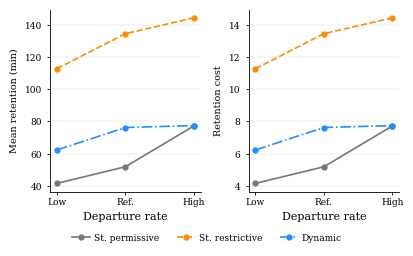


Departure retention and attributed autonomy cost
Sensitivity condition: boat_emphasis
Values are means per run. Retention cost is attributed service cost already included in total ABC cost; it uses illustrative rates.
Policy strategy Departure rate  Mean retention (min)  Retention cost
St. restrictive           Ref.            134.400000       13.440000
St. restrictive           High            144.233333       14.423333
St. restrictive            Low            112.733333       11.273333
 St. permissive           Ref.             51.900000        5.190000
 St. permissive           High             77.166667        7.716667
 St. permissive            Low             41.600000        4.160000
        Dynamic           Ref.             76.233333        7.623333
        Dynamic           High             77.433333        7.743333
        Dynamic            Low             62.300000        6.230000


In [16]:
retention_columns = {"forced_retention_minutes", "autonomy_restriction_cost_base"}
missing_retention_columns = retention_columns - set(runs.columns)
if missing_retention_columns:
    print(
        "Departure-retention metrics are absent from these output files. "
        "Rerun the updated simulator to populate: "
        + ", ".join(sorted(missing_retention_columns))
    )
else:
    retention_summary = (
        runs.groupby(["scenario", "profile_configuration"], observed=True)
        .agg(
            forced_retention_minutes=("forced_retention_minutes", "mean"),
            autonomy_restriction_cost_base=("autonomy_restriction_cost_base", "mean"),
        )
        .reset_index()
    )
    fig, axes = plt.subplots(1, 2, figsize=(4.05, 2.9))
    metric_specs = [
        ("forced_retention_minutes", "Mean retention (min)"),
        ("autonomy_restriction_cost_base", "Retention cost"),
    ]
    for ax, (metric, ylabel) in zip(axes, metric_specs):
        for strategy in scenario_order:
            strategy_data = retention_summary.loc[
                retention_summary["scenario"] == strategy
            ].set_index("profile_configuration").reindex(configuration_order)
            ax.plot(
                range(len(configuration_order)),
                strategy_data[metric],
                color=scenario_colors[strategy],
                linestyle=scenario_line_styles[strategy],
                marker="o",
                linewidth=1.2,
                markersize=3.5,
                label=scenario_labels[strategy],
            )
        ax.set_xticks(range(len(configuration_order)))
        ax.set_xticklabels(
            [configuration_labels[value] for value in configuration_order],
            rotation=0,
            ha="center",
        )
        ax.set_ylabel(ylabel, fontsize=7)
        ax.tick_params(labelsize=6.5)
        format_axis(ax)
    axes[0].set_xlabel("Departure rate")
    axes[1].set_xlabel("Departure rate")
    handles, labels = axes[1].get_legend_handles_labels()
    fig.legend(handles, labels, frameon=False, loc="lower center", ncol=3,
               fontsize=6.5, handletextpad=0.4, labelspacing=0.25,
               bbox_to_anchor=(0.5, 0.15))
    fig.tight_layout(rect=(0, 0.23, 1, 1), pad=0.5, w_pad=0.8)
    fig.savefig(plot_dir / "departure_retention_and_attributed_cost.pdf", bbox_inches="tight", pad_inches=0.02)
    plt.show()

if not missing_retention_columns:
    retention_print = retention_summary.rename(columns={
        "forced_retention_minutes": "Mean retention (min)",
        "autonomy_restriction_cost_base": "Retention cost",
    })
    print_plot_values("Departure retention and attributed autonomy cost", retention_print,
                      "Values are means per run. Retention cost is attributed service cost "
                      "already included in total ABC cost; it uses illustrative rates.")
